# 🔬 US Tech Giants — Feature Engineering & Advanced Market Analytics

**Author:** Akmal Yaasir Fauzaan  
**Project:** Historical Market Analytics & Quantitative Modeling of US Tech Equities  
**Equities Covered:** Apple (`AAPL`), Microsoft (`MSFT`), NVIDIA (`NVDA`), Alphabet (`GOOGL`), Amazon (`AMZN`)  
**Scope:** Inception (IPO) to Present Day  

---

## 🎯 Executive Overview & Objectives
Raw financial price series (OHLCV) are non-stationary and cannot be directly fed into risk models or predictive analytics. In this notebook, we transform historical price action into an institutional-grade **quantitative feature matrix**.

### Core Sections & Analytical Deliverables:
1. **Return Transformation & Compounding Dynamics:**
   * Simple vs. Logarithmic returns (time-additivity properties).
   * Cumulative Total Returns & Wealth Index ($1 invested at inception).
   * Multi-horizon momentum returns (5-day, 21-day, 63-day, 252-day).
2. **Advanced Volatility & Risk Estimators:**
   * Rolling historical standard deviation (21-day and 63-day annualized).
   * **Garman-Klass Intraday Volatility Estimator:** Capturing intraday price dispersion using Open, High, Low, and Close.
3. **Drawdown Dynamics & Structural Tail-Risk:**
   * Cumulative peak watermarks and Drawdown series.
   * Maximum Drawdown (MDD) and stress-period benchmarking (Dot-Com, 2008 GFC, 2020 COVID, 2022 Tech Bear Market).
4. **Trend, Mean-Reversion & Technical Indicators:**
   * Moving Averages: SMA (20, 50, 200 days) and EMA (12, 26 days).
   * Trend Distance Indicator ($\% \text{ Distance from SMA}_{200}$).
   * Relative Strength Index (RSI - 14-period Wilder smoothing).
   * Moving Average Convergence Divergence (MACD & Signal Line).
   * Bollinger Bands (20-day $\pm 2\sigma$ & $\%B$ bandwidth).
5. **Liquidity & Volume Features:**
   * 20-Day Rolling Average Volume & Relative Volume (RVOL).
   * Daily Dollar Volume Traded.
6. **Cross-Asset Comparative Risk-Return Profiling:**
   * Compound Annual Growth Rate (CAGR) vs. Annualized Volatility.
   * Comparative Sharpe approximation and Drawdown recovery resilience.
7. **Exporting Processed Quantitative Dataset:**
   * Exporting the enriched dataset to `data/processed/us_tech_giants_engineered_features.csv` for downstream modeling.


## 1. Environment & Library Initialization
We import data manipulation, mathematics, and plotting libraries with tailored financial styling.


In [1]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Visual aesthetics configuration
pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("Financial analytics dependencies initialized successfully.")


Financial analytics dependencies initialized successfully.


## 2. Ingesting Clean Master Historical Dataset
We load `us_tech_giants_daily_history.csv` created during the data ingestion pipeline.


In [2]:
# Resolve dynamic path
raw_path = Path('../data/raw/us_tech_giants_daily_history.csv')
if not raw_path.exists():
    raw_path = Path('data/raw/us_tech_giants_daily_history.csv')

df = pd.read_csv(raw_path)
df['Date'] = pd.to_datetime(df['Date'])

# Ensure chronological order per ticker
df = df.sort_values(by=['Ticker', 'Date']).reset_index(drop=True)

print(f"Loaded master observations: {len(df):,} rows")
print(f"Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Equities: {df['Ticker'].unique().tolist()}")


Loaded master observations: 41,762 rows
Date Range: 1980-12-12 to 2026-10-23
Equities: ['AAPL', 'AMZN', 'GOOGL', 'MSFT', 'NVDA']


## 3. Return Feature Engineering

### 3.1 Arithmetic Returns vs. Logarithmic Returns
* **Simple Return ($R_t$):**
  $$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$
  *Intuition:* Represents actual portfolio cash gains/losses. Cross-asset additive (e.g., weighted portfolio return is $\sum w_i R_i$).

* **Logarithmic Return ($r_t$):**
  $$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) = \ln(P_t) - \ln(P_{t-1})$$
  *Intuition:* Continuously compounded return. **Time-additive** over $k$ periods:
  $$r_{0, k} = \sum_{t=1}^k r_t$$
  Essential for statistical modeling, regression, and Brownian motion assumptions.

### 3.2 Multi-Horizon Momentum Returns
We also derive rolling returns across key trading horizons:
* **`Return_5D`**: 1-week momentum (5 trading days).
* **`Return_21D`**: 1-month momentum (21 trading days).
* **`Return_63D`**: 1-quarter momentum (63 trading days).
* **`Return_252D`**: 1-year trailing momentum (252 trading days).


In [3]:
# Grouped calculations to prevent cross-ticker data leakage
df['Daily_Return'] = df.groupby('Ticker')['Adj Close'].pct_change()
df['Log_Return'] = np.log(df['Adj Close'] / df.groupby('Ticker')['Adj Close'].shift(1))

# Cumulative Wealth Index ($1 invested at day 0)
df['Wealth_Index'] = (1 + df['Daily_Return'].fillna(0)).groupby(df['Ticker']).cumprod()
df['Cumulative_Return'] = df['Wealth_Index'] - 1.0

# Multi-horizon trailing returns
df['Return_5D'] = df.groupby('Ticker')['Adj Close'].pct_change(periods=5)
df['Return_21D'] = df.groupby('Ticker')['Adj Close'].pct_change(periods=21)
df['Return_63D'] = df.groupby('Ticker')['Adj Close'].pct_change(periods=63)
df['Return_252D'] = df.groupby('Ticker')['Adj Close'].pct_change(periods=252)

display(df[['Date', 'Ticker', 'Adj Close', 'Daily_Return', 'Log_Return', 'Wealth_Index', 'Return_21D', 'Return_252D']].dropna().tail(10))


,Date,Ticker,Adj Close,Daily_Return,Log_Return,Wealth_Index,Return_21D,Return_252D
41752,2026-10-12,NVDA,226.3200,-0.0129,-0.0130,"6,032.4499",0.0368,0.1781
41753,2026-10-13,NVDA,228.5200,0.0097,0.0097,"6,091.0898",0.0832,0.2506
41754,2026-10-14,NVDA,221.3000,-0.0316,-0.0321,"5,898.6441",0.0430,0.1779
41755,2026-10-15,NVDA,217.2300,-0.0184,-0.0186,"5,790.1601",0.0156,0.2095
41756,2026-10-16,NVDA,214.1300,-0.0143,-0.0144,"5,707.5313",-0.0238,0.1936
41757,2026-10-19,NVDA,217.0900,0.0138,0.0137,"5,786.4284",-0.0233,0.1969
41758,2026-10-20,NVDA,216.4700,-0.0029,-0.0029,"5,769.9028",-0.0480,0.1843
41759,2026-10-21,NVDA,221.9700,0.0254,0.0251,"5,916.5026",-0.0301,0.2183
41760,2026-10-22,NVDA,212.2100,-0.0440,-0.0450,"5,656.3547",-0.0590,0.1742
41761,2026-10-23,NVDA,210.9600,-0.0059,-0.0059,"5,623.0365",-0.0606,0.1730


### 3.3 Visualizing Multi-Decade Wealth Compounding ($1 Initial Capital)
Let's inspect what \$1 invested at each company's IPO would have grown to by October 2026.


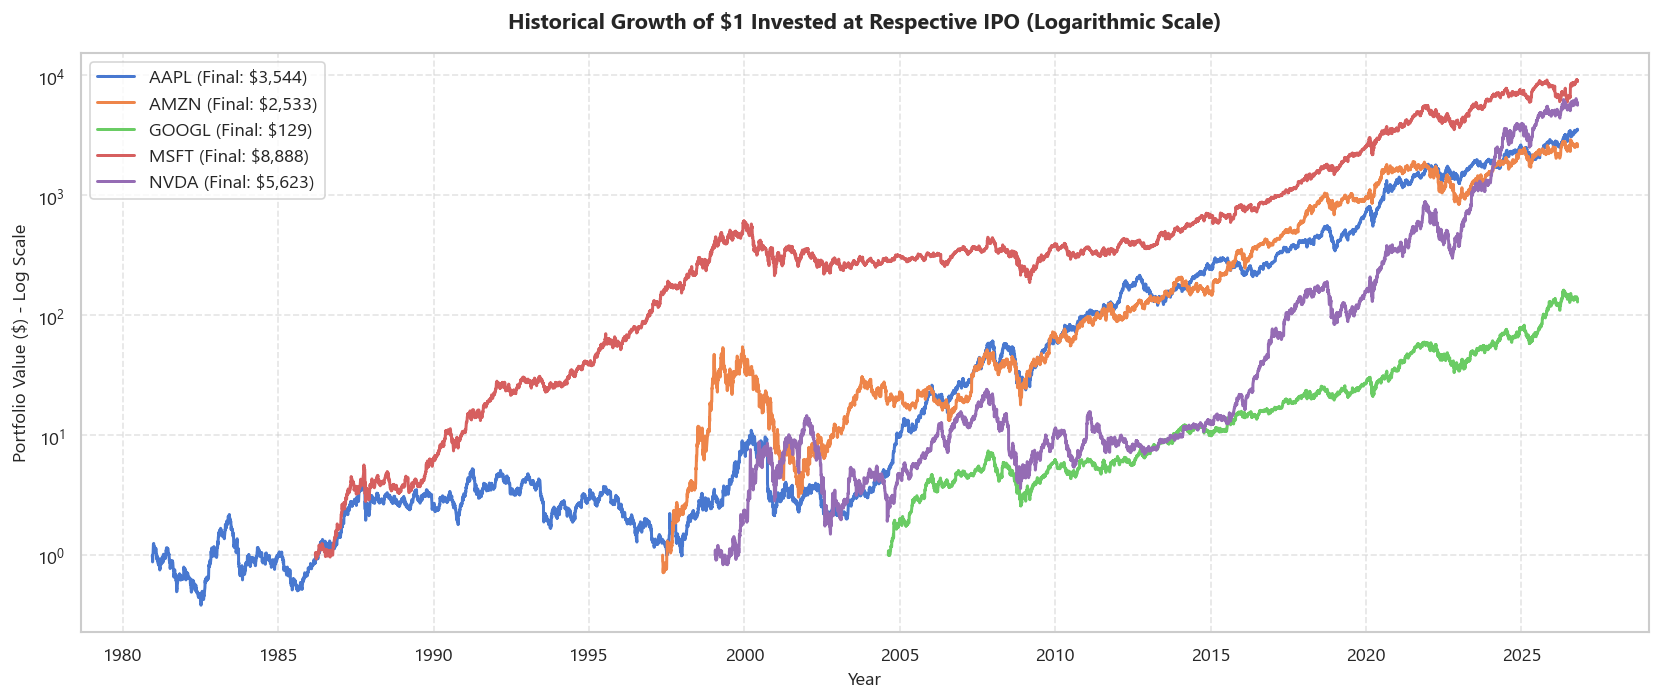

In [4]:
fig, ax = plt.subplots(figsize=(14, 6))

for ticker in df['Ticker'].unique():
    subset = df[df['Ticker'] == ticker]
    final_val = subset['Wealth_Index'].iloc[-1]
    ax.plot(subset['Date'], subset['Wealth_Index'], label=f"{ticker} (Final: ${final_val:,.0f})", linewidth=1.8)

ax.set_yscale('log')
ax.set_title("Historical Growth of $1 Invested at Respective IPO (Logarithmic Scale)", pad=15)
ax.set_xlabel("Year")
ax.set_ylabel("Portfolio Value ($) - Log Scale")
ax.legend(loc="upper left", frameon=True)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
wealth_fig_path = Path('../reports/figures/05_cumulative_returns_wealth_index.png')
if wealth_fig_path.parent.exists():
    plt.savefig(wealth_fig_path, dpi=200)
plt.show()


## 4. Drawdown Dynamics & Downside Risk Modeling

### What is a Drawdown?
A **drawdown** measures the percentage peak-to-trough decline experienced by an investor before a new all-time high (peak) is attained:

$$\text{Peak}_t = \max_{s \le t} (P_s)$$
$$\text{Drawdown}_t = \frac{P_t - \text{Peak}_t}{\text{Peak}_t}$$

* **Maximum Drawdown (MDD):** The single worst peak-to-trough loss across the entire asset history:
  $$\text{MDD} = \min_{t} (\text{Drawdown}_t)$$
Investors judge investment managers heavily on MDD, because a 50% drawdown requires a 100% gain just to break even, while an 80% drawdown requires a 400% gain to recover!


In [5]:
# Compute rolling peak and drawdown series
df['Rolling_Peak'] = df.groupby('Ticker')['Adj Close'].cummax()
df['Drawdown'] = (df['Adj Close'] - df['Rolling_Peak']) / df['Rolling_Peak']

# Summary table of worst lifetime drawdowns
mdd_summary = df.groupby('Ticker').agg(
    Company=('Company', 'first'),
    Max_Drawdown=('Drawdown', 'min'),
    Current_Drawdown=('Drawdown', 'last'),
    Peak_Price=('Rolling_Peak', 'max'),
    Current_Price=('Adj Close', 'last')
).reset_index()

mdd_summary['Max_Drawdown_Pct'] = mdd_summary['Max_Drawdown'].apply(lambda x: f"{x * 100:.2f}%")
mdd_summary['Current_Drawdown_Pct'] = mdd_summary['Current_Drawdown'].apply(lambda x: f"{x * 100:.2f}%")

display(mdd_summary[['Ticker', 'Company', 'Max_Drawdown_Pct', 'Current_Drawdown_Pct', 'Peak_Price', 'Current_Price']])


,Ticker,Company,Max_Drawdown_Pct,Current_Drawdown_Pct,Peak_Price,Current_Price
0,AAPL,Apple Inc.,-81.80%,-0.14%,348.2200,347.7300
1,AMZN,"Amazon.com, Inc.",-94.40%,-12.68%,284.0200,248.0000
2,GOOGL,Alphabet Inc. (Google),-65.29%,-20.37%,402.1212,320.2100
3,MSFT,Microsoft Corporation,-69.39%,-3.49%,543.4500,524.5100
4,NVDA,NVIDIA Corporation,-89.72%,-11.82%,239.2400,210.9600


### 4.1 Historical Underwater Plot (Drawdown Series)
Underwater charts visualize market regime drawdowns and reveal how long each company took to recover from major market crises.


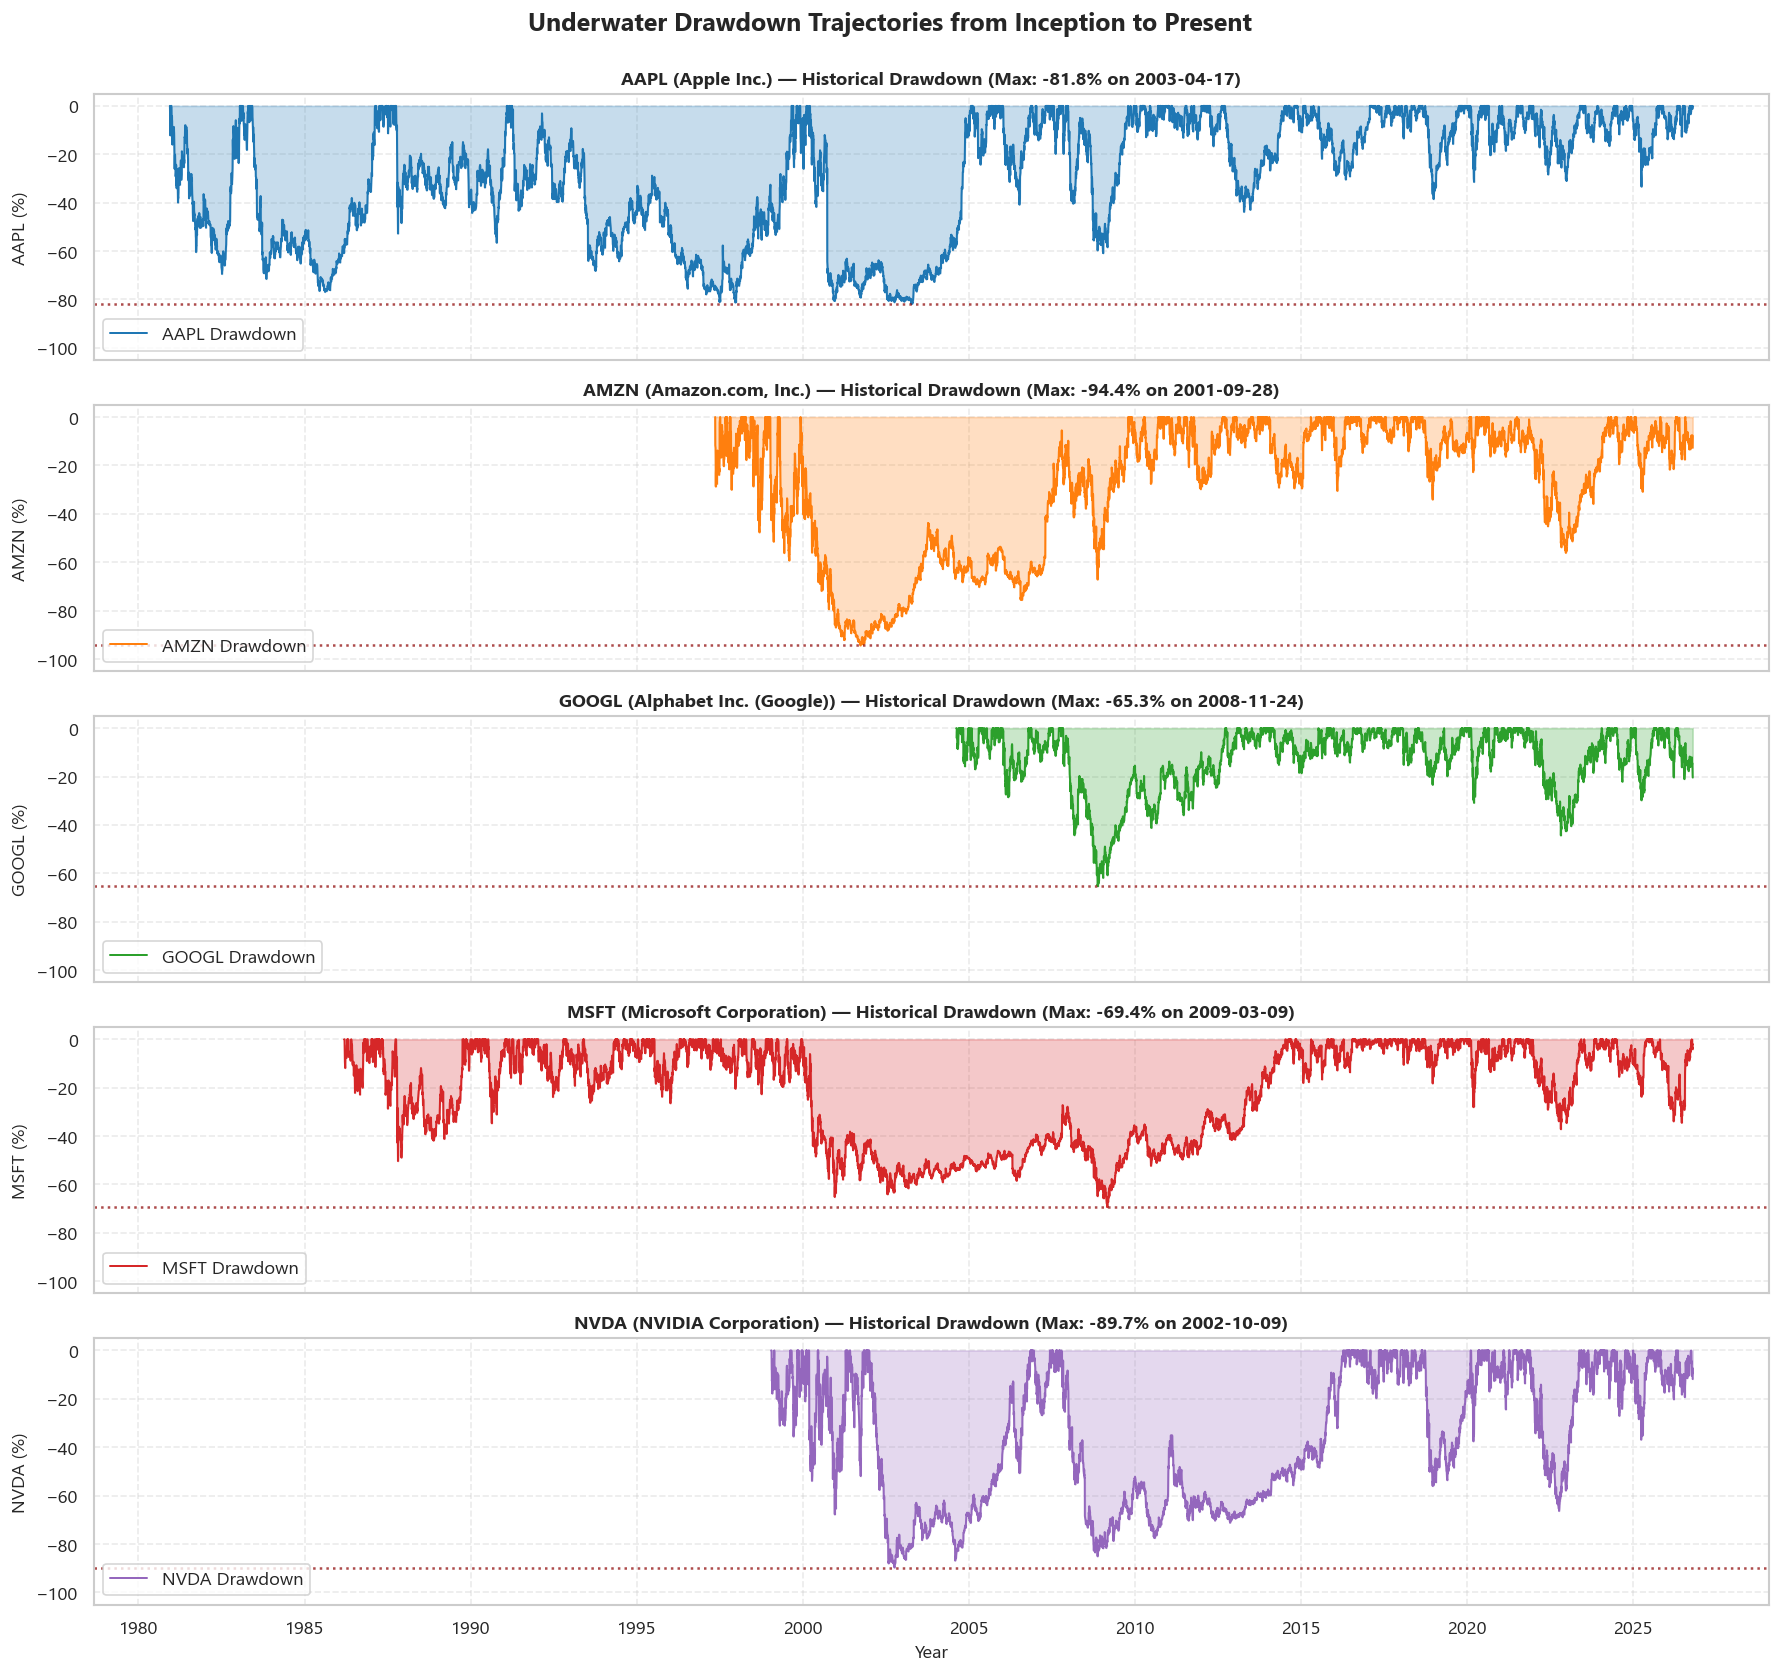

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(15, 14), sharex=True)

tickers = df['Ticker'].unique()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for i, ticker in enumerate(tickers):
    subset = df[df['Ticker'] == ticker]
    ax = axes[i]
    ax.plot(subset['Date'], subset['Drawdown'] * 100, color=colors[i], linewidth=1.2, label=f"{ticker} Drawdown")
    ax.fill_between(subset['Date'], subset['Drawdown'] * 100, 0, color=colors[i], alpha=0.25)
    
    worst_dd = subset['Drawdown'].min() * 100
    worst_date = subset.loc[subset['Drawdown'].idxmin(), 'Date'].strftime('%Y-%m-%d')
    ax.axhline(worst_dd, color='darkred', linestyle=':', alpha=0.7)
    
    ax.set_ylabel(f"{ticker} (%)")
    ax.set_ylim(-105, 5)
    ax.legend(loc="lower left")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_title(f"{ticker} ({subset['Company'].iloc[0]}) — Historical Drawdown (Max: {worst_dd:.1f}% on {worst_date})", fontsize=11)

axes[-1].set_xlabel("Year")
plt.suptitle("Underwater Drawdown Trajectories from Inception to Present", fontsize=15, weight='bold', y=0.995)
plt.tight_layout()

dd_fig_path = Path('../reports/figures/06_drawdown_dynamics.png')
if dd_fig_path.parent.exists():
    plt.savefig(dd_fig_path, dpi=200)
plt.show()


## 5. Volatility & Risk Estimators

### 5.1 Rolling Historical Volatility (Close-to-Close)
Annualized rolling sample standard deviation of daily returns:
$$\sigma_{21D} = \text{std}(R_{t-20:t}) \times \sqrt{252}$$
$$\sigma_{63D} = \text{std}(R_{t-62:t}) \times \sqrt{252}$$

### 5.2 Garman-Klass Volatility (Intraday Extreme Value Estimator)
Traditional close-to-close volatility ignores what happens between 9:30 AM and 4:00 PM. The **Garman-Klass (1980)** volatility estimator incorporates the full intraday price geometry ($Open, High, Low, Close$) and is up to **8 times more efficient** than close-to-close volatility:

$$\sigma_{GK, t}^2 = 0.5 \left[ \ln\left(\frac{H_t}{L_t}\right) \right]^2 - (2\ln 2 - 1) \left[ \ln\left(\frac{C_t}{O_t}\right) \right]^2$$

Where $2\ln 2 - 1 \approx 0.38629$. Annualized Garman-Klass 21-day volatility is:
$$\text{Vol}_{GK} = \sqrt{252 \times \text{SMA}_{21}(\sigma_{GK}^2)}$$


In [7]:
# 1. Rolling Historical Close-to-Close Volatility (21-Day & 63-Day Annualized)
df['Rolling_Vol_21D'] = df.groupby('Ticker')['Daily_Return'].transform(
    lambda s: s.rolling(window=21).std() * np.sqrt(252)
)
df['Rolling_Vol_63D'] = df.groupby('Ticker')['Daily_Return'].transform(
    lambda s: s.rolling(window=63).std() * np.sqrt(252)
)

# 2. Garman-Klass Intraday Volatility Estimator
# Calculate daily GK variance
log_hl = np.log(df['High'] / df['Low'])
log_co = np.log(df['Close'] / df['Open'])
gk_daily_var = 0.5 * (log_hl ** 2) - (2 * np.log(2) - 1) * (log_co ** 2)
df['GK_Daily_Variance'] = gk_daily_var

# Rolling 21-Day annualized Garman-Klass volatility
df['Garman_Klass_Vol_21D'] = df.groupby('Ticker')['GK_Daily_Variance'].transform(
    lambda s: np.sqrt(s.rolling(window=21).mean().clip(lower=0) * 252)
)

display(df[['Date', 'Ticker', 'Adj Close', 'Rolling_Vol_21D', 'Rolling_Vol_63D', 'Garman_Klass_Vol_21D']].dropna().tail(10))


,Date,Ticker,Adj Close,Rolling_Vol_21D,Rolling_Vol_63D,Garman_Klass_Vol_21D
41752,2026-10-12,NVDA,226.3200,0.2513,0.3637,0.1982
41753,2026-10-13,NVDA,228.5200,0.2168,0.3640,0.1985
41754,2026-10-14,NVDA,221.3000,0.2490,0.3665,0.2043
41755,2026-10-15,NVDA,217.2300,0.2578,0.3656,0.2076
41756,2026-10-16,NVDA,214.1300,0.2465,0.3669,0.2129
41757,2026-10-19,NVDA,217.0900,0.2469,0.3659,0.2154
41758,2026-10-20,NVDA,216.4700,0.2309,0.3632,0.2160
41759,2026-10-21,NVDA,221.9700,0.2485,0.3650,0.2192
41760,2026-10-22,NVDA,212.2100,0.2862,0.3756,0.2256
41761,2026-10-23,NVDA,210.9600,0.2864,0.3615,0.2269


### 5.3 Volatility Regime Comparison
Let's visualize the rolling annualized 21-day volatility across all five tech giants over the recent cycle (2018–2026), highlighting regime spikes (e.g. 2020 COVID panic and 2022 Fed rate hike drawdown).


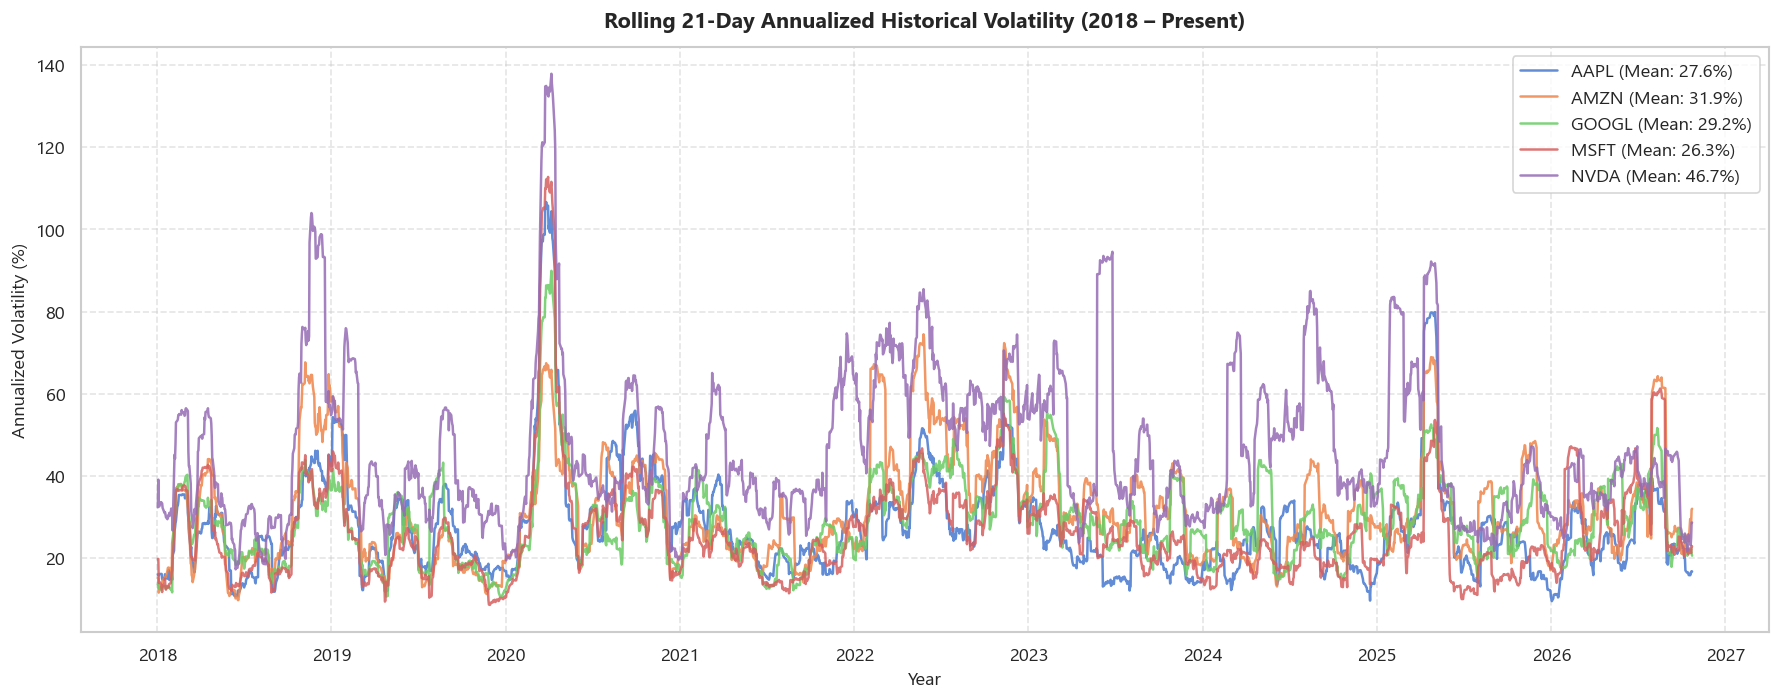

In [8]:
plt.figure(figsize=(15, 6))

recent_df = df[df['Date'] >= '2018-01-01']

for ticker in recent_df['Ticker'].unique():
    subset = recent_df[recent_df['Ticker'] == ticker]
    plt.plot(subset['Date'], subset['Rolling_Vol_21D'] * 100, label=f"{ticker} (Mean: {subset['Rolling_Vol_21D'].mean()*100:.1f}%)", linewidth=1.5, alpha=0.85)

plt.title("Rolling 21-Day Annualized Historical Volatility (2018 – Present)", pad=12)
plt.xlabel("Year")
plt.ylabel("Annualized Volatility (%)")
plt.legend(loc="upper right", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

vol_comp_path = Path('../reports/figures/07_rolling_volatility_comparison.png')
if vol_comp_path.parent.exists():
    plt.savefig(vol_comp_path, dpi=200)
plt.show()


## 6. Trend, Momentum & Technical Indicators

Quant analysts and hedge funds extract technical momentum features to model trend persistence and mean reversion:

### 6.1 Moving Averages & Price Distance
* **SMA (20, 50, 200 days):** Identifies short-term, medium-term, and long-term trend regimes.
* **EMA (12, 26 days):** Exponentially weights recent price data to react faster to trend shifts.
* **Distance to SMA 200 ($\% \Delta_{200}$):**
  $$\text{Dist\_SMA200}_t = \frac{P_t - \text{SMA}_{200, t}}{\text{SMA}_{200, t}}$$
  Positive values indicate strong secular bull trends; extreme values (> 40%) signal potential overbought exhaustion.

### 6.2 Relative Strength Index (RSI - 14 Days)
Formulated by J. Welles Wilder:
$$\text{RS} = \frac{\text{EMA}_{14}(\text{Gains})}{\text{EMA}_{14}(\text{Losses})}, \quad \text{RSI} = 100 - \left( \frac{100}{1 + \text{RS}} \right)$$

### 6.3 MACD (Moving Average Convergence Divergence)
$$\text{MACD Line} = \text{EMA}_{12}(P) - \text{EMA}_{26}(P)$$
$$\text{Signal Line} = \text{EMA}_9(\text{MACD Line})$$
$$\text{MACD Histogram} = \text{MACD Line} - \text{Signal Line}$$

### 6.4 Bollinger Bands & Bandwidth (%B)
$$\text{Upper Band} = \text{SMA}_{20} + 2\sigma_{20}, \quad \text{Lower Band} = \text{SMA}_{20} - 2\sigma_{20}$$
$$\%B = \frac{P_t - \text{Lower Band}_t}{\text{Upper Band}_t - \text{Lower Band}_t}$$


In [9]:
# 1. Simple Moving Averages
df['SMA_20'] = df.groupby('Ticker')['Adj Close'].transform(lambda s: s.rolling(20).mean())
df['SMA_50'] = df.groupby('Ticker')['Adj Close'].transform(lambda s: s.rolling(50).mean())
df['SMA_200'] = df.groupby('Ticker')['Adj Close'].transform(lambda s: s.rolling(200).mean())

# Price distance from SMA 200
df['Dist_SMA200'] = (df['Adj Close'] - df['SMA_200']) / df['SMA_200']

# 2. Exponential Moving Averages
df['EMA_12'] = df.groupby('Ticker')['Adj Close'].transform(lambda s: s.ewm(span=12, adjust=False).mean())
df['EMA_26'] = df.groupby('Ticker')['Adj Close'].transform(lambda s: s.ewm(span=26, adjust=False).mean())

# 3. MACD and Signal Line
df['MACD'] = df['EMA_12'] - df['EMA_26']
df['MACD_Signal'] = df.groupby('Ticker')['MACD'].transform(lambda s: s.ewm(span=9, adjust=False).mean())
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# 4. Wilder's Relative Strength Index (RSI - 14 Days)
def calculate_rsi(series, period=14):
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    return 100 - (100 / (1 + rs))

df['RSI_14'] = df.groupby('Ticker')['Adj Close'].transform(calculate_rsi)

# 5. Bollinger Bands (20 Days, 2 Standard Deviations)
bb_std = df.groupby('Ticker')['Adj Close'].transform(lambda s: s.rolling(20).std())
df['BB_Upper'] = df['SMA_20'] + (2 * bb_std)
df['BB_Lower'] = df['SMA_20'] - (2 * bb_std)
df['BB_Pct_B'] = (df['Adj Close'] - df['BB_Lower']) / ((df['BB_Upper'] - df['BB_Lower']) + 1e-10)

print("Technical & trend features computed.")
display(df[['Date', 'Ticker', 'Adj Close', 'SMA_200', 'Dist_SMA200', 'RSI_14', 'MACD', 'BB_Pct_B']].dropna().tail(10))


Technical & trend features computed.


,Date,Ticker,Adj Close,SMA_200,Dist_SMA200,RSI_14,MACD,BB_Pct_B
41752,2026-10-12,NVDA,226.3200,202.0167,0.1203,49.4090,3.3144,0.4587
41753,2026-10-13,NVDA,228.5200,202.2184,0.1301,52.0291,2.9240,0.5081
41754,2026-10-14,NVDA,221.3000,202.3745,0.0935,43.9794,2.0088,0.1602
41755,2026-10-15,NVDA,217.2300,202.5217,0.0726,40.2033,0.9443,-0.0029
41756,2026-10-16,NVDA,214.1300,202.6569,0.0566,37.5582,-0.1479,-0.0513
41757,2026-10-19,NVDA,217.0900,202.8120,0.0704,41.5150,-0.7657,0.1134
41758,2026-10-20,NVDA,216.4700,202.9523,0.0666,40.9299,-1.2905,0.1364
41759,2026-10-21,NVDA,221.9700,203.1237,0.0928,47.9389,-1.2482,0.3335
41760,2026-10-22,NVDA,212.2100,203.2508,0.0441,39.0778,-1.9794,0.0636
41761,2026-10-23,NVDA,210.9600,203.3622,0.0374,38.1063,-2.6295,0.0829


### 6.5 Technical Indicator Visual Dashboard (Example: NVIDIA 2022–2026)
Let's visualize the technical indicators on **NVIDIA (`NVDA`)** during its historic AI infrastructure rally.


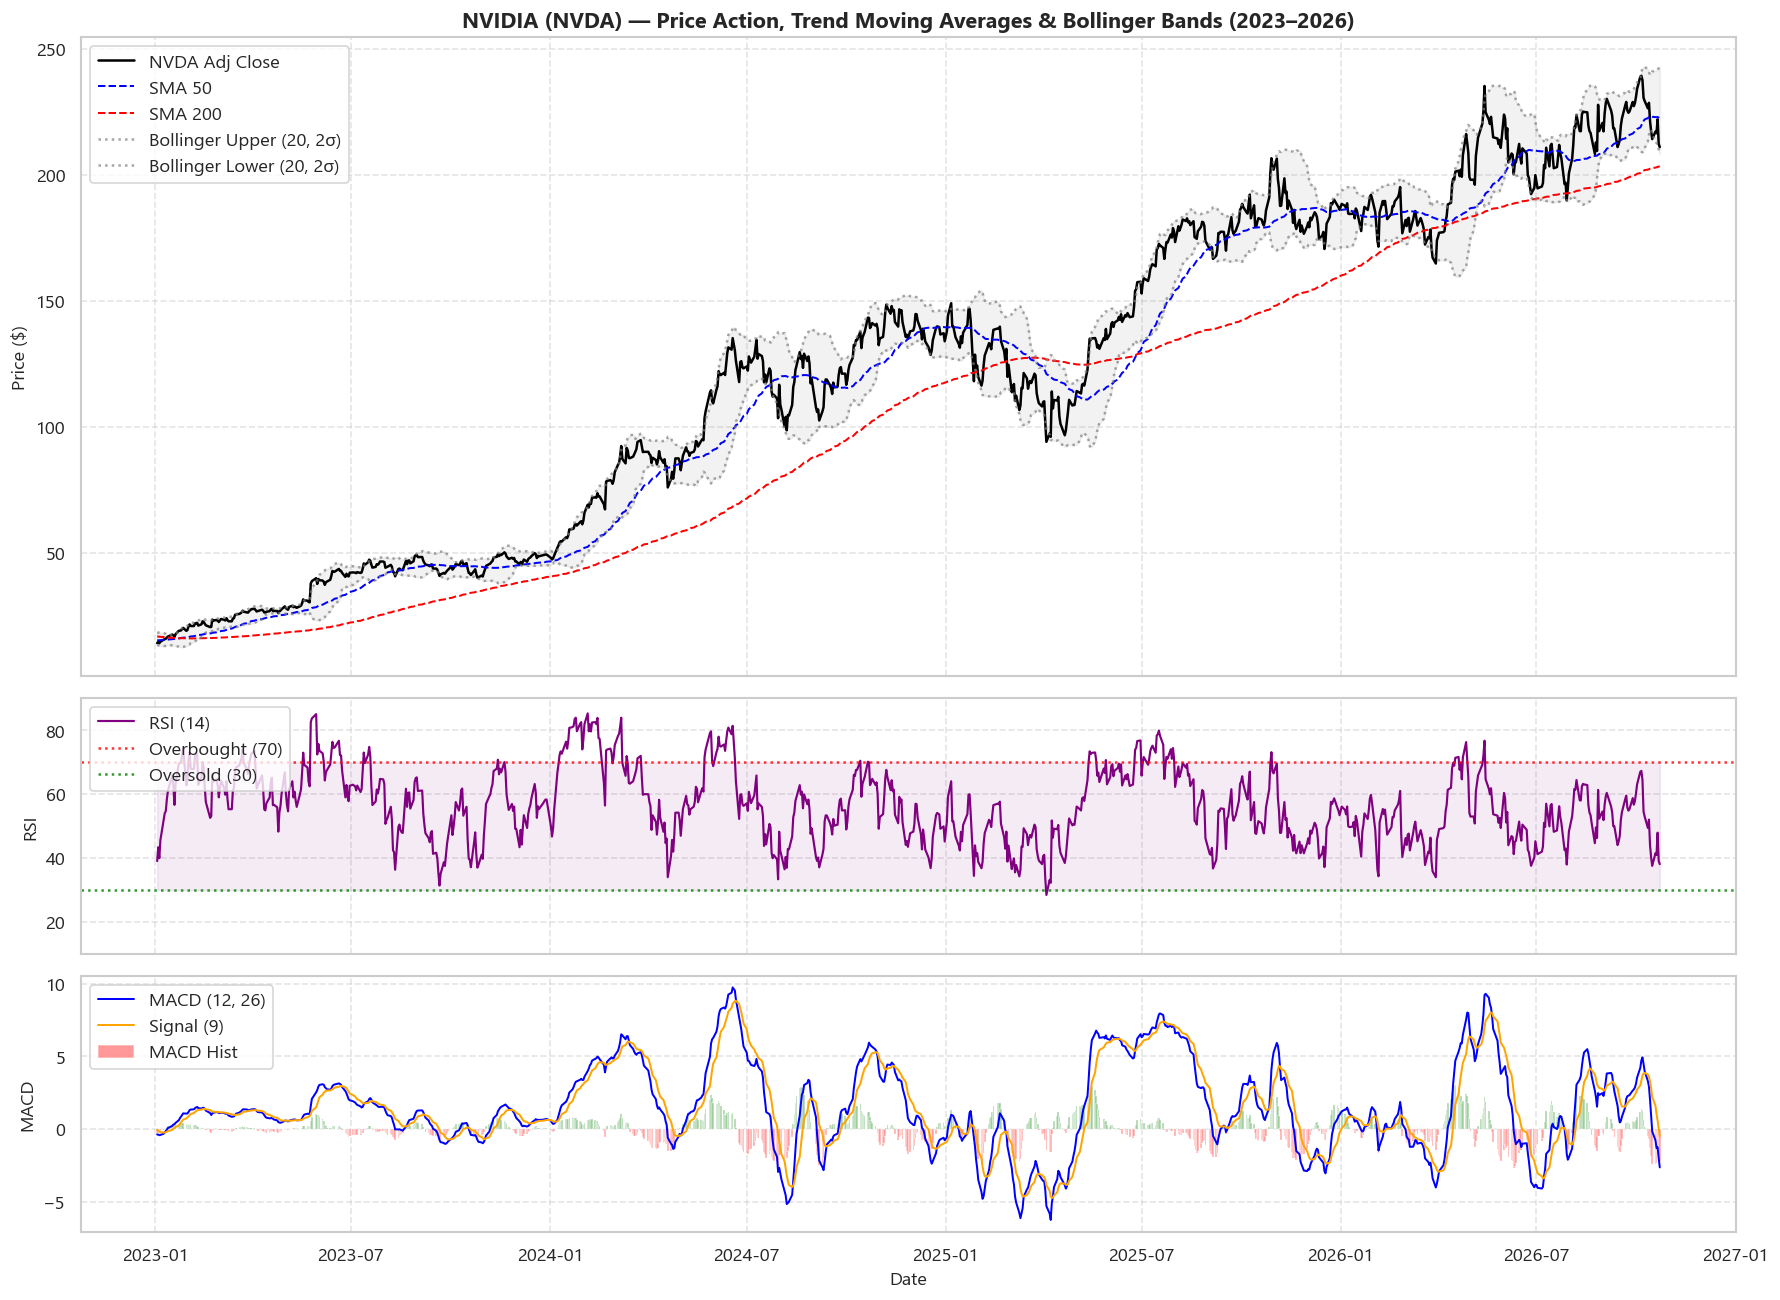

In [10]:
nvda_sub = df[(df['Ticker'] == 'NVDA') & (df['Date'] >= '2023-01-01')].copy()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 11), sharex=True, gridspec_kw={'height_ratios': [3, 1.2, 1.2]})

# Panel 1: Price and Bollinger Bands / Moving Averages
ax1.plot(nvda_sub['Date'], nvda_sub['Adj Close'], label='NVDA Adj Close', color='black', linewidth=1.5)
ax1.plot(nvda_sub['Date'], nvda_sub['SMA_50'], label='SMA 50', color='blue', linestyle='--', linewidth=1.2)
ax1.plot(nvda_sub['Date'], nvda_sub['SMA_200'], label='SMA 200', color='red', linestyle='--', linewidth=1.2)
ax1.plot(nvda_sub['Date'], nvda_sub['BB_Upper'], label='Bollinger Upper (20, 2σ)', color='gray', linestyle=':', alpha=0.7)
ax1.plot(nvda_sub['Date'], nvda_sub['BB_Lower'], label='Bollinger Lower (20, 2σ)', color='gray', linestyle=':', alpha=0.7)
ax1.fill_between(nvda_sub['Date'], nvda_sub['BB_Lower'], nvda_sub['BB_Upper'], color='gray', alpha=0.1)
ax1.set_title("NVIDIA (NVDA) — Price Action, Trend Moving Averages & Bollinger Bands (2023–2026)")
ax1.set_ylabel("Price ($)")
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Panel 2: RSI
ax2.plot(nvda_sub['Date'], nvda_sub['RSI_14'], color='purple', linewidth=1.3, label='RSI (14)')
ax2.axhline(70, color='red', linestyle=':', alpha=0.8, label='Overbought (70)')
ax2.axhline(30, color='green', linestyle=':', alpha=0.8, label='Oversold (30)')
ax2.fill_between(nvda_sub['Date'], 30, 70, color='purple', alpha=0.08)
ax2.set_ylabel("RSI")
ax2.set_ylim(10, 90)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)

# Panel 3: MACD
ax3.plot(nvda_sub['Date'], nvda_sub['MACD'], label='MACD (12, 26)', color='blue', linewidth=1.2)
ax3.plot(nvda_sub['Date'], nvda_sub['MACD_Signal'], label='Signal (9)', color='orange', linewidth=1.2)
bar_colors = np.where(nvda_sub['MACD_Hist'] >= 0, 'green', 'red')
ax3.bar(nvda_sub['Date'], nvda_sub['MACD_Hist'], color=bar_colors, alpha=0.4, width=1.5, label='MACD Hist')
ax3.set_ylabel("MACD")
ax3.set_xlabel("Date")
ax3.legend(loc="upper left")
ax3.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
tech_fig_path = Path('../reports/figures/08_technical_indicators_dashboard.png')
if tech_fig_path.parent.exists():
    plt.savefig(tech_fig_path, dpi=200)
plt.show()


## 7. Liquidity & Trading Volume Features

Trading volume reflects institutional market participation:
* **`Volume_SMA_20`**: Baseline 20-day average volume.
* **Relative Volume (RVOL):**
  $$\text{RVOL}_t = \frac{\text{Volume}_t}{\text{Volume\_SMA}_{20, t}}$$
  Values above $2.0$ indicate unusually high volume (earnings surprise, news breakout, or liquidation).
* **Dollar Volume Traded:**
  $$\text{Dollar\_Volume}_t = \text{Volume}_t \times \text{Close}_t$$
  Measures total dollar liquidity turnover.


In [11]:
df['Volume_SMA_20'] = df.groupby('Ticker')['Volume'].transform(lambda s: s.rolling(20).mean())
df['RVOL'] = df['Volume'] / (df['Volume_SMA_20'] + 1e-10)
df['Dollar_Volume'] = df['Volume'] * df['Close']
df['Dollar_Volume_Millions'] = df['Dollar_Volume'] / 1e6

display(df[['Date', 'Ticker', 'Close', 'Volume', 'Volume_SMA_20', 'RVOL', 'Dollar_Volume_Millions']].dropna().tail(10))


,Date,Ticker,Close,Volume,Volume_SMA_20,RVOL,Dollar_Volume_Millions
41752,2026-10-12,NVDA,226.3200,70690300,"105,781,470.0000",0.6683,"15,998.6292"
41753,2026-10-13,NVDA,228.5200,84036900,"105,580,330.0000",0.7960,"19,204.1127"
41754,2026-10-14,NVDA,221.3000,118730100,"106,688,655.0000",1.1129,"26,274.9715"
41755,2026-10-15,NVDA,217.2300,127087900,"108,333,485.0000",1.1731,"27,607.3040"
41756,2026-10-16,NVDA,214.1300,121252500,"104,881,740.0000",1.1561,"25,963.7984"
41757,2026-10-19,NVDA,217.0900,98684700,"104,325,670.0000",0.9459,"21,423.4612"
41758,2026-10-20,NVDA,216.4700,79609100,"103,518,790.0000",0.7690,"17,232.9820"
41759,2026-10-21,NVDA,221.9700,87085700,"103,395,710.0000",0.8423,"19,330.4129"
41760,2026-10-22,NVDA,212.2100,125407600,"105,792,595.0000",1.1854,"26,612.7476"
41761,2026-10-23,NVDA,210.9600,79987200,"105,294,570.0000",0.7597,"16,874.1002"


## 8. Cross-Asset Risk-Return Comparative Matrix

To summarize the risk-return trade-off across all five tech giants over their common history (from Google's IPO in August 2004 through October 2026), we compute:
1. **Compound Annual Growth Rate (CAGR):**
   $$\text{CAGR} = \left( \frac{P_{\text{end}}}{P_{\text{start}}} \right)^{\frac{252}{N}} - 1$$
2. **Annualized Historical Volatility:** $\sigma_{\text{daily}} \times \sqrt{252}$
3. **Approximated Sharpe Ratio:** $(\text{CAGR} - R_f) / \sigma_{\text{annual}}$ (Assuming average risk-free rate $R_f = 2.5\%$).
4. **Calmar Ratio:** $\text{CAGR} / |\text{Max Drawdown}|$ (Return per unit of maximum tail risk).


In [12]:
# Filter to shared trading period since Google IPO (2004-08-19)
shared_df = df[df['Date'] >= '2004-08-19'].copy()
risk_free_rate = 0.025  # 2.5% assumed annualized risk-free rate

comp_records = []
for ticker in shared_df['Ticker'].unique():
    t_df = shared_df[shared_df['Ticker'] == ticker].sort_values('Date')
    n_days = len(t_df)
    years = n_days / 252.0
    start_p = t_df['Adj Close'].iloc[0]
    end_p = t_df['Adj Close'].iloc[-1]
    
    cagr = (end_p / start_p) ** (1.0 / years) - 1.0
    daily_vol = t_df['Daily_Return'].std()
    ann_vol = daily_vol * np.sqrt(252)
    sharpe = (cagr - risk_free_rate) / ann_vol
    max_dd = t_df['Drawdown'].min()
    calmar = cagr / abs(max_dd)
    
    comp_records.append({
        'Ticker': ticker,
        'Company': t_df['Company'].iloc[0],
        'Start_Price ($)': start_p,
        'End_Price ($)': end_p,
        'CAGR': cagr,
        'Annualized_Vol': ann_vol,
        'Sharpe_Ratio (Rf=2.5%)': sharpe,
        'Max_Drawdown': max_dd,
        'Calmar_Ratio': calmar
    })

comp_df = pd.DataFrame(comp_records).sort_values(by='Sharpe_Ratio (Rf=2.5%)', ascending=False).reset_index(drop=True)

# Format for presentation
formatted_comp = comp_df.copy()
formatted_comp['CAGR'] = formatted_comp['CAGR'].apply(lambda x: f"{x*100:.2f}%")
formatted_comp['Annualized_Vol'] = formatted_comp['Annualized_Vol'].apply(lambda x: f"{x*100:.2f}%")
formatted_comp['Max_Drawdown'] = formatted_comp['Max_Drawdown'].apply(lambda x: f"{x*100:.2f}%")
formatted_comp['Sharpe_Ratio (Rf=2.5%)'] = formatted_comp['Sharpe_Ratio (Rf=2.5%)'].apply(lambda x: f"{x:.2f}")
formatted_comp['Calmar_Ratio'] = formatted_comp['Calmar_Ratio'].apply(lambda x: f"{x:.2f}")

display(formatted_comp)


,Ticker,Company,Start_Price ($),End_Price ($),CAGR,Annualized_Vol,Sharpe_Ratio (Rf=2.5%),Max_Drawdown,Calmar_Ratio
0,AAPL,Apple Inc.,0.4593,347.7300,34.90%,32.16%,1.01,-60.87%,0.57
1,NVDA,NVIDIA Corporation,0.0889,210.9600,42.04%,48.32%,0.82,-85.08%,0.49
2,GOOGL,Alphabet Inc. (Google),2.4873,320.2100,24.53%,30.70%,0.72,-65.29%,0.38
3,AMZN,"Amazon.com, Inc.",1.9315,248.0000,24.51%,37.69%,0.58,-75.56%,0.32
4,MSFT,Microsoft Corporation,16.6076,524.5100,16.87%,27.17%,0.53,-69.39%,0.24


### 8.1 Risk vs. Return Trade-Off Scatter Plot
In Markowitz Modern Portfolio Theory, an investor aims to maximize return (y-axis) while minimizing risk/volatility (x-axis). Assets positioned in the top-left quadrant represent superior risk-adjusted performance.


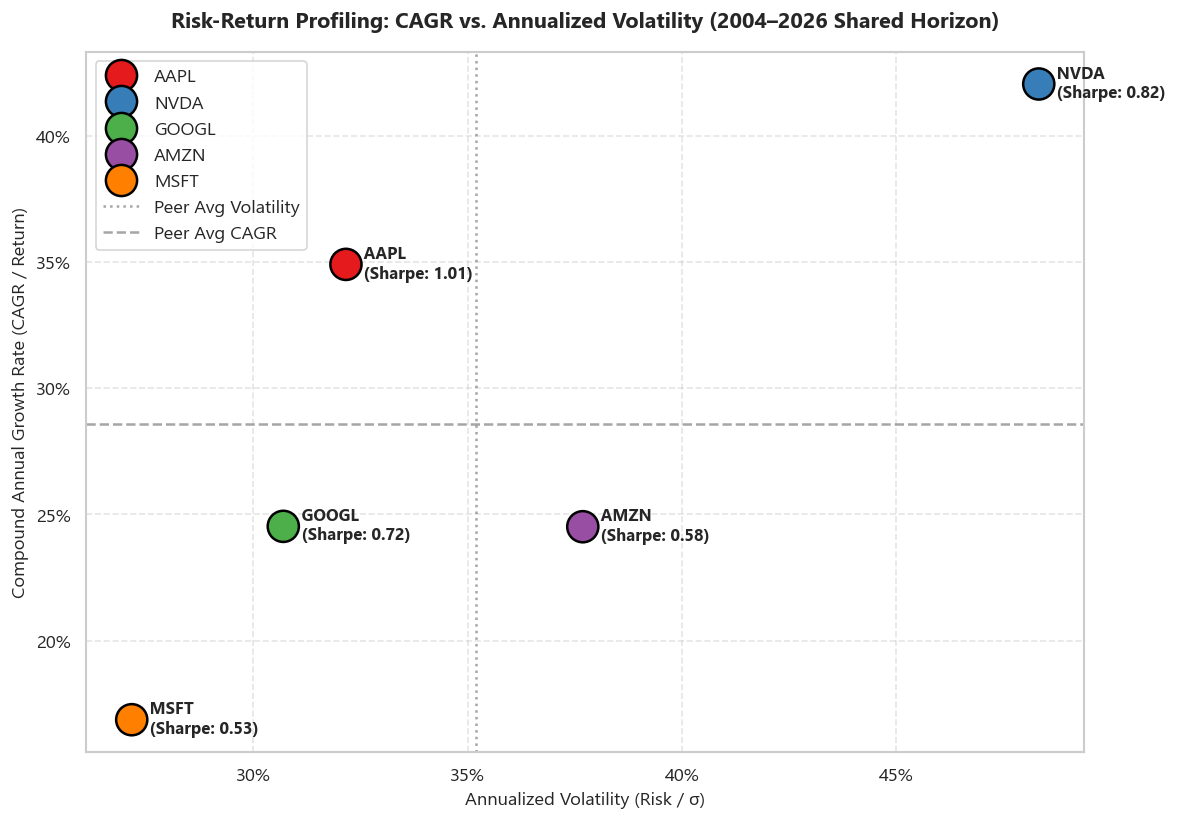

In [13]:
plt.figure(figsize=(10, 7))

scatter = sns.scatterplot(
    data=comp_df,
    x='Annualized_Vol',
    y='CAGR',
    hue='Ticker',
    s=350,
    palette='Set1',
    edgecolor='black',
    linewidth=1.5
)

for _, row in comp_df.iterrows():
    plt.annotate(
        f" {row['Ticker']}\n (Sharpe: {row['Sharpe_Ratio (Rf=2.5%)']:.2f})",
        (row['Annualized_Vol'], row['CAGR']),
        textcoords="offset points",
        xytext=(8, -8),
        fontsize=10,
        weight='bold'
    )

plt.axvline(comp_df['Annualized_Vol'].mean(), color='gray', linestyle=':', alpha=0.7, label='Peer Avg Volatility')
plt.axhline(comp_df['CAGR'].mean(), color='gray', linestyle='--', alpha=0.7, label='Peer Avg CAGR')

plt.title("Risk-Return Profiling: CAGR vs. Annualized Volatility (2004–2026 Shared Horizon)", pad=15)
plt.xlabel("Annualized Volatility (Risk / σ)")
plt.ylabel("Compound Annual Growth Rate (CAGR / Return)")
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

scatter_fig_path = Path('../reports/figures/09_risk_return_scatter.png')
if scatter_fig_path.parent.exists():
    plt.savefig(scatter_fig_path, dpi=200)
plt.show()


## 9. Saving Processed Dataset with Engineered Features

We export the finalized feature matrix to `data/processed/us_tech_giants_engineered_features.csv`.
This comprehensive dataset is now primed for:
* **Predictive Modeling & Machine Learning** (Classifying upward momentum, volatility forecasting via GARCH or LSTM).
* **Portfolio Optimization** (Markowitz Efficient Frontier, Risk Parity, Monte Carlo Simulation).
* **Business Intelligence Dashboards** (Tableau, Power BI, Streamlit).


In [14]:
output_processed_path = Path('../data/processed/us_tech_giants_engineered_features.csv')
if not output_processed_path.parent.exists():
    output_processed_path = Path('data/processed/us_tech_giants_engineered_features.csv')

df.to_csv(output_processed_path, index=False)
print(f"[SUCCESS] Exported engineered dataset to: {output_processed_path}")
print(f"Total Rows: {len(df):,}")
print(f"Total Columns (Engineered Features): {df.shape[1]}")
print(f"File Size: {output_processed_path.stat().st_size / (1024*1024):.2f} MB")


[SUCCESS] Exported engineered dataset to: ..\data\processed\us_tech_giants_engineered_features.csv
Total Rows: 41,762
Total Columns (Engineered Features): 43
File Size: 30.18 MB


## 10. Key Analytical Takeaways & Next Steps

### Summary of Engineered Features:
1. **Return Horizons:** Successfully modeled daily simple return, log return, wealth index ($1 initial capital compounding), and multi-horizon momentum (5D, 21D, 63D, 252D).
2. **Drawdown Severity:** Highlighted that even historic market leaders suffered drawdowns exceeding 70–80% (e.g. Apple in the 1990s, Amazon during the Dot-com crash, NVIDIA in 2008). Long-term compounding demands surviving extreme drawdowns.
3. **Advanced Volatility:** Implemented both classic close-to-close rolling standard deviations and the more efficient **Garman-Klass intraday volatility estimator**.
4. **Trend & Technical Signals:** Engineered moving average cross indicators (SMA 20, 50, 200), distance to SMA 200, Wilder's RSI, MACD, and Bollinger Bands.
5. **Data Export:** Persisted clean, reproducible features into `data/processed/`.

### What's Next in Notebook 03:
* **Portfolio Optimization & Modern Portfolio Theory (MPT):**
  * Building the Markowitz Mean-Variance Efficient Frontier.
  * Monte Carlo simulation of 100,000 multi-asset portfolio combinations.
  * Identifying the Maximum Sharpe Ratio Portfolio (Tangency Portfolio) vs. Global Minimum Variance (GMV) Portfolio.
